# Machine-learning analysis of the PIM-1 cavity-size distribution

Regression models that learn the smooth cavity-size distribution of PIM-1 (a polymer of intrinsic microporosity) from a noisy histogram of cavity diameters, with the models compared against the noise limit of the data.

**Data.** `PIM_1.unq` is a plain-text table with no header. Only the 4th column, the cavity diameter in Å, is used. This `.unq` file is generated after running a Cavity Energetic Sizing Algorithm (CESA) on the already equilibrated polymer system, using a software called VACUUMMS, developed by Frank T Willmore (DOI: https://doi.org/10.1145/2335755.2335826).

**What the notebook does**
1. **Data:** loads the diameters and builds a normalised histogram (`bin_centers`, `hist_N`). The histogram is the dataset for the models: bin-centre diameter in, fraction of cavities per bin out.
2. **Models:** Polynomial + Ridge, Support Vector Regression (RBF), k-Nearest Neighbours, Random Forest, Gradient Boosting, a neural network (MLP) and a Gaussian Process (scikit-learn). Hyperparameters are tuned with `GridSearchCV` inside nested cross-validation (inner 3-fold, outer 5-fold), so the scores are not over-optimistic. The Gaussian Process has no grid: it learns its kernel hyperparameters from the data.
3. **Evaluation:** MSE and R², judged against the noise floor and noise ceiling that the histogram's counting noise sets for any model (computed analytically). A stress test with contiguous, unshuffled folds shows how the models behave when extrapolating.

**Key result** (`bin_width = 0.025`): Gradient Boosting is the best model (R² = 0.861, MSE 1.29x the noise floor) against a noise ceiling of R² = 0.893. kNN, the Gaussian Process, SVR and the MLP also meet the success criterion (R² within 0.05 of the ceiling and MSE within 1.5x the floor), while Random Forest narrowly misses it and Polynomial + Ridge is clearly behind. The models cannot extrapolate beyond the sampled diameters.

**How to run**
- Put `PIM_1.unq` in the same folder as the notebook.
- Requires Python with `numpy`, `pandas`, `matplotlib`, `scikit-learn` and Jupyter.
- `bin_width` in the first code cell sets the histogram resolution. A smaller `bin_width` gives a noisier target and a lower achievable R². Change it and use **Restart & Run All**; every later cell recomputes from it.
- The full run takes a few minutes, mostly tuning the MLP and the boosted trees.

# Data

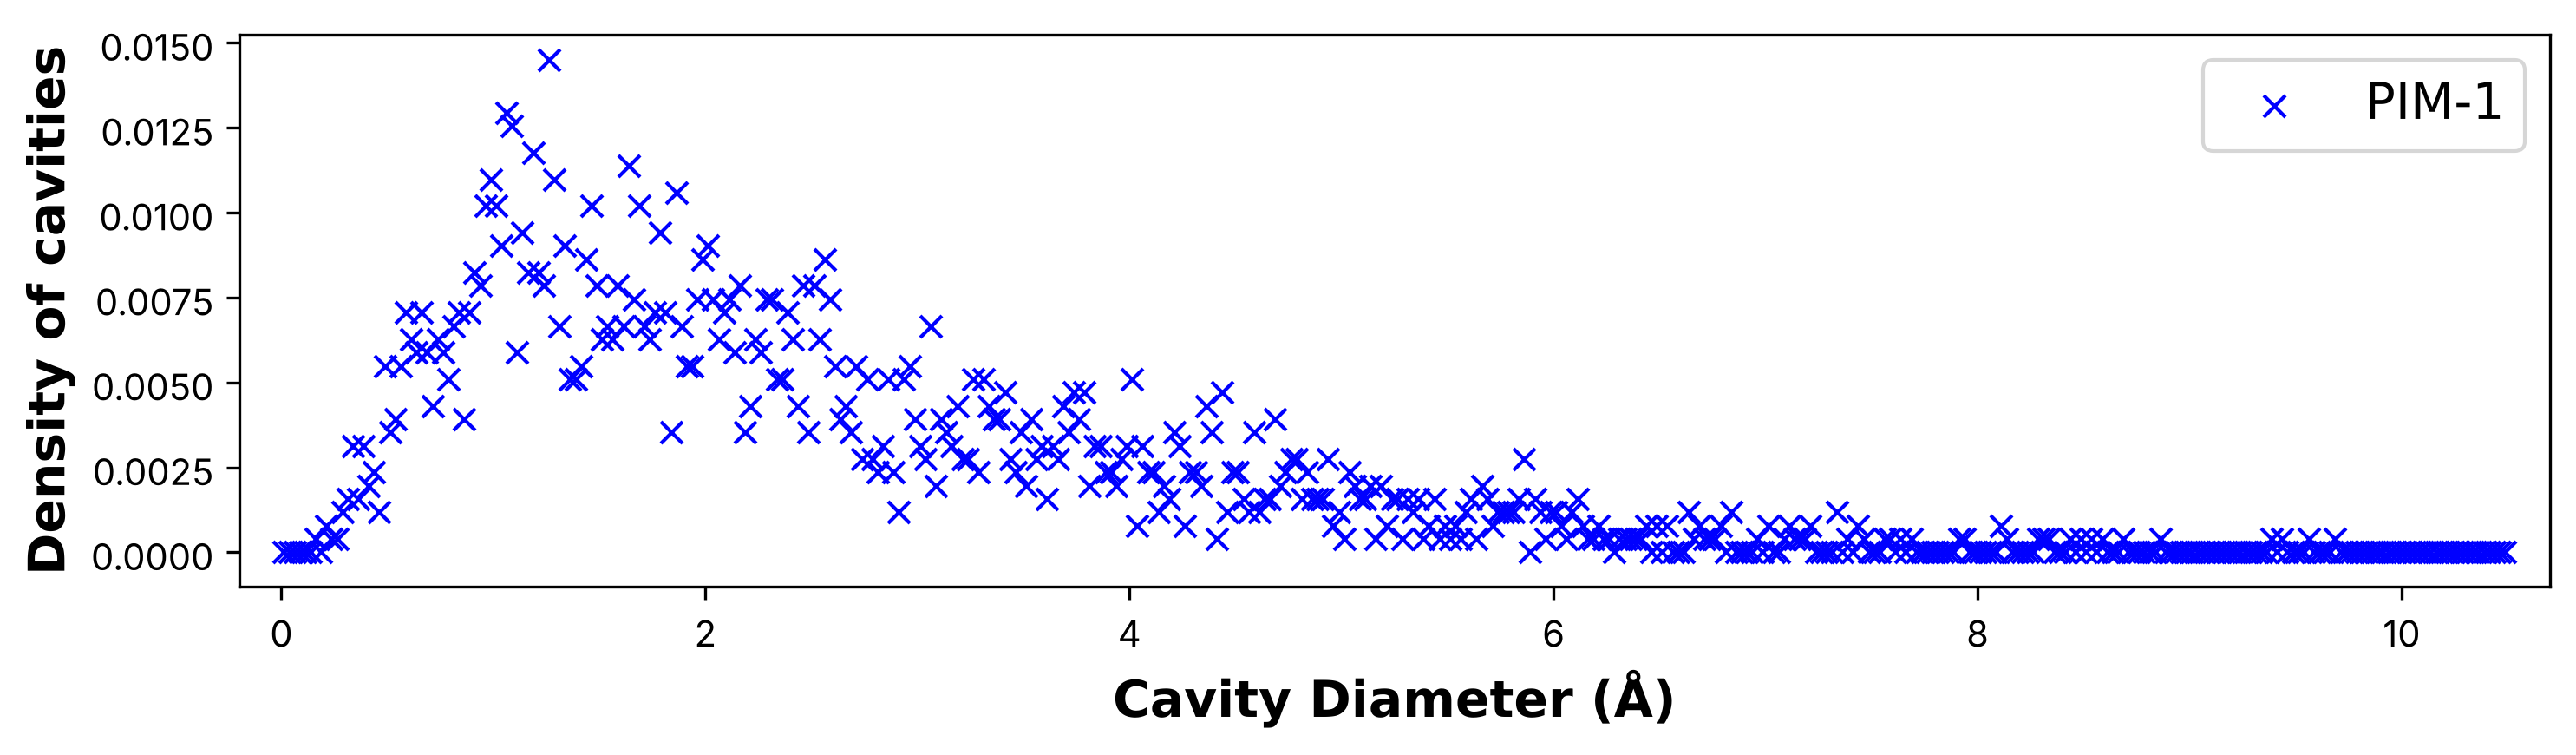

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- Load data and extraction ---
file = "PIM_1.unq"
data = np.loadtxt(file)[:, 3]  # diameters (4th column)

# --- Histogram settings --- (We can tune the bin width for the dataset to be more or less noisy. The smaller the bin width, the noisier)
min_d, max_d = 0.0, 10.5
bin_width = 0.025
bins = np.arange(min_d, max_d + bin_width, bin_width)
bin_centers = 0.5 * (bins[:-1] + bins[1:])

# --- Compute normalized histograms (point estimates) ---
hist, _ = np.histogram(data, bins=bins)
hist_N = hist / sum(hist)

fig, ax = plt.subplots(figsize=(10, 3), dpi=300) # figsize=(width, height)
ax.scatter(bin_centers, hist_N, color='blue', linewidth=1.0, label="PIM-1", marker="x")
ax.set_xlabel('Cavity Diameter (Å)', fontsize=14, fontweight='bold', family='Arial')
ax.set_ylabel('Density of cavities', fontsize=14, fontweight='bold', family='Arial')
ax.set_xlim(min_d-0.2, max_d+0.2)
ax.set_ylim(bottom=-0.001)
legend = plt.legend(fontsize=25, frameon=True, loc='upper right', prop={'family': 'Arial', 'size':14})

ax.grid(alpha=0)
plt.tight_layout()
plt.show()

---
# Machine-learning analysis of the cavity-diameter distribution
This section **builds on the first cell** (run it first) and reuses its variables: `data`, `min_d`, `max_d`, `bin_width`, `bins`, `bin_centers`, `hist` and `hist_N`. The models learn the normalised histogram:
**X = `bin_centers`** (cavity diameter, Å) → **y = `hist_N`** (fraction of cavities per bin). Only the diameter column is used.

### ⚙️ Changing the binning
Edit `bin_width` in the **first cell**, then use **Run → Restart & Run All**. Everything below (hyperparameter grids, tuning, metrics, plots, text) recomputes from it.

A **smaller `bin_width`** gives more, narrower bins with fewer cavities in each, so the target is **noisier** and the achievable R² is lower. A larger `bin_width` gives a smoother target but less resolution.

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel as Ck, RBF, WhiteKernel
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_val_predict, cross_validate, validation_curve
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"],
                     "axes.labelweight": "bold", "axes.labelsize": 12, "figure.dpi": 110})
SEED = 0

# Model dataset from the first cell's variables
X = bin_centers.reshape(-1, 1)          # feature: bin-centre diameter
n_bins = len(bin_centers)
if n_bins < 30:
    raise ValueError(f"bin_width = {bin_width} gives only {n_bins} bins; use a smaller bin_width (need >= 30 bins for 5-fold nested CV).")

print(f"bin_width = {bin_width}  ->  {n_bins} bins")

bin_width = 0.025  ->  420 bins


---
# Which algorithms are suitable, and which hyperparameters need tuning?

**Problem type:** supervised **regression** with one feature (diameter) and a smooth, right-skewed, noisy target. With one feature and a few hundred points, large models are unnecessary; the main risk is **fitting the noise**, so each model's regularisation hyperparameter matters most.

| Algorithm | Why it is suitable | Hyperparameters tuned |
|---|---|---|
| Polynomial + Ridge | Simple, smooth, interpretable baseline | polynomial degree, ridge α |
| SVR (RBF kernel) | Smooth non-linear fit, robust to noise through ε | C, γ, ε |
| k-Nearest Neighbours | Non-parametric local average | k, weighting |
| Random Forest | Averages many trees, little tuning needed | n_estimators, max_depth, min_samples_leaf |
| Gradient Boosting | Strong general-purpose regressor | n_estimators, learning_rate, max_depth, subsample |
| Neural net (MLP) | Flexible smooth function approximator | hidden layer sizes, α (L2), learning rate |
| Gaussian Process | Smooth non-parametric fit; its hyperparameters are learned from the data | kernel length-scale and noise level (optimised automatically by marginal likelihood, so no grid) |

**Tuning protocol:** *nested* cross-validation. An inner 3-fold `GridSearchCV` picks the hyperparameters; an outer 5-fold loop (shuffled) scores the result on bins the tuning never saw, so the reported scores are not optimistic. The k values for kNN are automatically limited to what the chosen `bin_width` can support.

In [3]:
def scaled(model):
    # standardise the (tiny) target so SVR / kNN / MLP / GP hyperparameters work on a sensible scale
    return TransformedTargetRegressor(regressor=model, transformer=StandardScaler())

K_MAX = int(n_bins * 0.8 * (2 / 3))                     # largest training set seen by kNN in the inner CV
knn_ks = [k for k in (5, 10, 15, 25, 40) if k <= K_MAX] or [max(1, K_MAX)]

MODELS = {
    "Poly + Ridge": (scaled(make_pipeline(PolynomialFeatures(), StandardScaler(), Ridge())),
                     {"regressor__polynomialfeatures__degree": [3, 5, 7, 9, 11],
                      "regressor__ridge__alpha": [1e-3, 1e-1, 1, 10]}),
    "SVR (RBF)":    (scaled(make_pipeline(StandardScaler(), SVR())),
                     {"regressor__svr__C": [1, 10, 100],
                      "regressor__svr__gamma": [0.1, 0.5, 1, 2, 5],
                      "regressor__svr__epsilon": [0.01, 0.1, 0.3]}),
    "kNN":          (scaled(KNeighborsRegressor()),
                     {"regressor__n_neighbors": knn_ks,
                      "regressor__weights": ["uniform", "distance"]}),
    "Random Forest": (RandomForestRegressor(random_state=SEED),
                     {"n_estimators": [100, 300], "max_depth": [3, 5, 8, None],
                      "min_samples_leaf": [1, 5, 10, 20]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=SEED),
                     {"n_estimators": [100, 300], "learning_rate": [0.01, 0.05, 0.1],
                      "max_depth": [2, 3, 4], "subsample": [0.7, 1.0]}),
    "MLP":          (scaled(make_pipeline(StandardScaler(), MLPRegressor(max_iter=3000, random_state=SEED))),
                     {"regressor__mlpregressor__hidden_layer_sizes": [(16,), (32, 32), (64, 64)],
                      "regressor__mlpregressor__alpha": [1e-4, 1e-2, 1],
                      "regressor__mlpregressor__learning_rate_init": [1e-3, 1e-2]}),
    "Gaussian Process": (scaled(GaussianProcessRegressor(Ck(1.0) * RBF(1.0) + WhiteKernel(0.1),
                                                         n_restarts_optimizer=2, random_state=SEED)),
                     {}),   # kernel hyperparameters are optimised internally, so there is no grid to search
}
# print("grid sizes:", {k: int(np.prod([len(v) for v in g.values()])) for k, (_, g) in MODELS.items()})

In [4]:
outer = KFold(5, shuffle=True, random_state=SEED)
inner = KFold(3, shuffle=True, random_state=SEED)

rows, best_params, best_models = [], {}, {}
for name, (est, grid) in MODELS.items():
    # (a) nested CV -> unbiased performance estimate
    search = GridSearchCV(est, grid, cv=inner, scoring="neg_mean_squared_error", n_jobs=-1)
    cv = cross_validate(search, X, hist_N, cv=outer, scoring={"mse": "neg_mean_squared_error", "r2": "r2"})
    rows.append({"Model": name, "MSE": (-cv["test_mse"]).mean(), "R²": cv["test_r2"].mean()})
    # (b) tune once on all bins -> hyperparameters to report and use in the plots
    full = GridSearchCV(est, grid, cv=KFold(5, shuffle=True, random_state=SEED),
                        scoring="neg_mean_squared_error", n_jobs=-1).fit(X, hist_N)
    best_models[name] = full.best_estimator_
    best_params[name] = {k.split("__")[-1]: v for k, v in full.best_params_.items()}
    print(f"{name:18s} MSE={rows[-1]['MSE']:.3e}  R2={rows[-1]['R²']:.3f}")

results = pd.DataFrame(rows).set_index("Model")
pd.DataFrame({"best hyperparameters (tuned on all bins)": best_params})

Poly + Ridge       MSE=1.711e-06  R2=0.802


SVR (RBF)          MSE=1.313e-06  R2=0.846


kNN                MSE=1.279e-06  R2=0.850


Random Forest      MSE=1.390e-06  R2=0.839


Gradient Boosting  MSE=1.194e-06  R2=0.861


MLP                MSE=1.297e-06  R2=0.845


Gaussian Process   MSE=1.300e-06  R2=0.846


,best hyperparameters (tuned on all bins)
Poly + Ridge,"{'degree': 11, 'alpha': 0.001}"
SVR (RBF),"{'C': 100, 'epsilon': 0.1, 'gamma': 5}"
kNN,"{'n_neighbors': 5, 'weights': 'uniform'}"
Random Forest,"{'max_depth': 5, 'min_samples_leaf': 5, 'n_est..."
Gradient Boosting,"{'learning_rate': 0.01, 'max_depth': 3, 'n_est..."
MLP,"{'alpha': 0.01, 'hidden_layer_sizes': (32, 32)..."
Gaussian Process,{}


In [5]:
# the Gaussian Process has no grid: its kernel hyperparameters are learned from the data
print("GP learned kernel:", best_models["Gaussian Process"].regressor_.kernel_)

GP learned kernel: 0.841**2 * RBF(length_scale=0.647) + WhiteKernel(noise_level=0.133)


### How sensitive is each model to its main hyperparameter?
Training score vs cross-validated score. Where the two curves separate, the model is fitting noise.

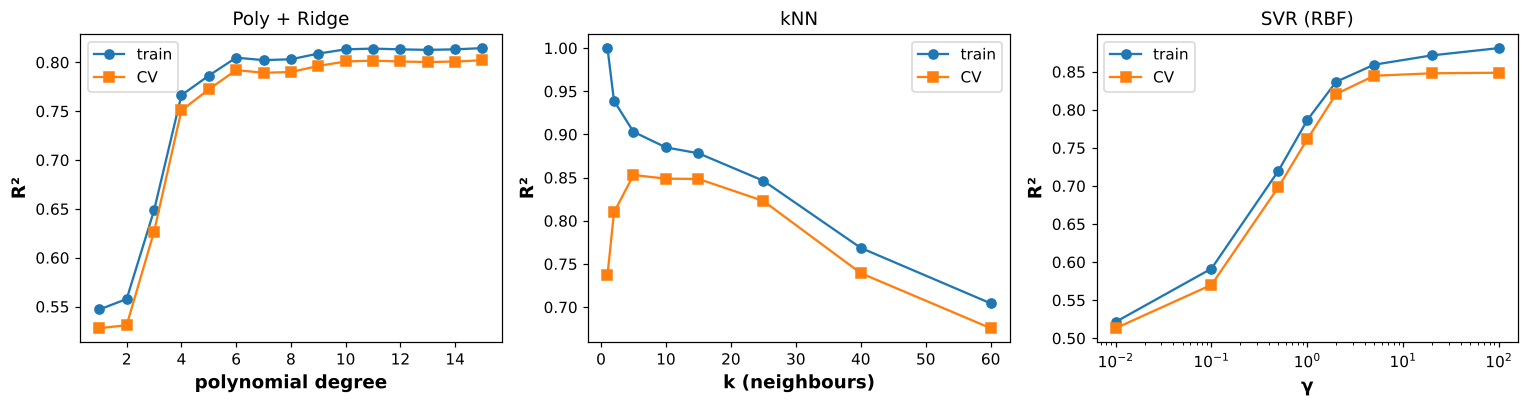

In [6]:
cvk = KFold(5, shuffle=True, random_state=SEED)

def vcurve(ax, name, param, rng, title, xlabel, log=False):
    tr, va = validation_curve(clone(MODELS[name][0]), X, hist_N, param_name=param, param_range=rng,
                              cv=cvk, scoring="r2", n_jobs=-1)
    ax.plot(rng, tr.mean(1), "o-", label="train"); ax.plot(rng, va.mean(1), "s-", label="CV")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("R²"); ax.legend()
    if log: ax.set_xscale("log")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
poly = clone(MODELS["Poly + Ridge"][0]).set_params(regressor__ridge__alpha=1e-3)
degs = list(range(1, 16))
tr, va = validation_curve(poly, X, hist_N, param_name="regressor__polynomialfeatures__degree",
                          param_range=degs, cv=cvk, scoring="r2", n_jobs=-1)
ax[0].plot(degs, tr.mean(1), "o-", label="train"); ax[0].plot(degs, va.mean(1), "s-", label="CV")
ax[0].set_title("Poly + Ridge"); ax[0].set_xlabel("polynomial degree"); ax[0].set_ylabel("R²"); ax[0].legend()
ks = [k for k in (1, 2, 5, 10, 15, 25, 40, 60) if k <= int(n_bins * 0.8)]
vcurve(ax[1], "kNN", "regressor__n_neighbors", ks, "kNN", "k (neighbours)")
vcurve(ax[2], "SVR (RBF)", "regressor__svr__gamma", [0.01, 0.1, 0.5, 1, 2, 5, 20, 100], "SVR (RBF)", "γ", log=True)
plt.tight_layout(); plt.show()

---
# What counts as success?
**Metrics (regression):**
- **MSE** = mean((y − ŷ)²) with y = `hist_N`, the error in the units of the target (fraction-of-cavities²).
- **R²** = 1 − SSE/SST, the fraction of the variance of the curve that is explained (1 = perfect, 0 = no better than predicting the mean).

Classification metrics (ROC-AUC, F1) do not apply because the target is continuous.

### A realistic target: the noise ceiling
The target histogram is itself a noisy estimate of the true distribution, so even a *perfect* model would not reach R² = 1 against it. With N cavities the count in each bin is multinomial, so the noise variance per bin is p(1−p)/N. This gives a noise floor for the MSE and a ceiling for R² (computed analytically, no resampling):

In [7]:
noise_var = np.mean(hist_N * (1 - hist_N) / hist.sum())          # expected MSE of the true density vs a noisy histogram
total_var = np.var(hist_N)
r2_ceiling = 1 - noise_var / total_var
R2_TARGET, MSE_TARGET = r2_ceiling - 0.05, 1.5 * noise_var
print(f"bin_width = {bin_width}  ({n_bins} bins)")
print(f"noise-floor MSE   = {noise_var:.3e}")
print(f"R² noise ceiling  = {r2_ceiling:.3f}")
print(f"success criterion: R² >= {R2_TARGET:.3f}  AND  MSE <= {MSE_TARGET:.3e} (1.5 x noise floor)")

bin_width = 0.025  (420 bins)
noise-floor MSE   = 9.281e-07
R² noise ceiling  = 0.893
success criterion: R² >= 0.843  AND  MSE <= 1.392e-06 (1.5 x noise floor)


**Success criterion:** cross-validated R² within 0.05 of the ceiling **and** MSE within 1.5× the noise floor. A score far above the ceiling would signal overfitting, not a better model. "MSE / noise floor" is comparable across different `bin_width` (raw MSE and R² are not, because the target's scale and noise change with the bin count).

In [8]:
res = results.copy()
res["MSE / noise floor"] = res["MSE"] / noise_var
res["Meets criterion"] = np.where((res["R²"] >= R2_TARGET) & (res["MSE"] <= MSE_TARGET), "yes", "no")
res = res.sort_values("MSE")
display(res.style.format({"MSE": "{:.3e}", "R²": "{:.3f}", "MSE / noise floor": "{:.2f}"})
           .background_gradient(subset=["R²"], cmap="Greens"))
print("Scores come from nested 5-fold CV (shuffled).")

,MSE,R²,MSE / noise floor,Meets criterion
Model,,,,
Gradient Boosting,1.194e-06,0.861,1.29,yes
kNN,1.279e-06,0.850,1.38,yes
MLP,1.297e-06,0.845,1.40,yes
Gaussian Process,1.300e-06,0.846,1.40,yes
SVR (RBF),1.313e-06,0.846,1.41,yes
Random Forest,1.390e-06,0.839,1.50,no
Poly + Ridge,1.711e-06,0.802,1.84,no


Scores come from nested 5-fold CV (shuffled).


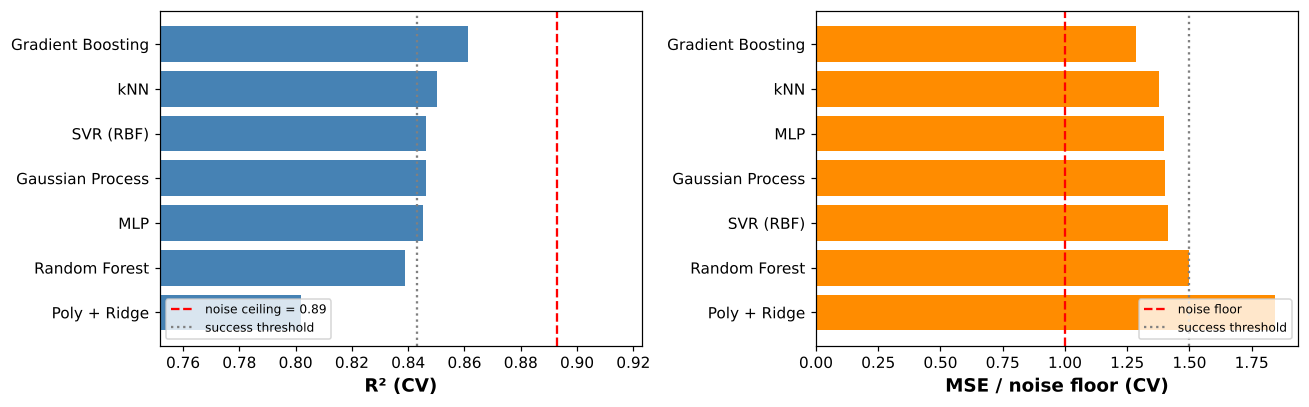

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
r = res.sort_values("R²")
ax[0].barh(r.index, r["R²"], color="steelblue")
ax[0].axvline(r2_ceiling, color="red", ls="--", label=f"noise ceiling = {r2_ceiling:.2f}")
ax[0].axvline(R2_TARGET, color="gray", ls=":", label="success threshold")
ax[0].set_xlim(min(r["R²"].min(), R2_TARGET) - 0.05, max(r["R²"].max(), r2_ceiling) + 0.03)
ax[0].set_xlabel("R² (CV)"); ax[0].legend(loc="lower left", fontsize=8)
r = res.sort_values("MSE", ascending=False)
ax[1].barh(r.index, r["MSE / noise floor"], color="darkorange")
ax[1].axvline(1.0, color="red", ls="--", label="noise floor")
ax[1].axvline(1.5, color="gray", ls=":", label="success threshold")
ax[1].set_xlabel("MSE / noise floor (CV)"); ax[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### Fitted curves, parity and residuals

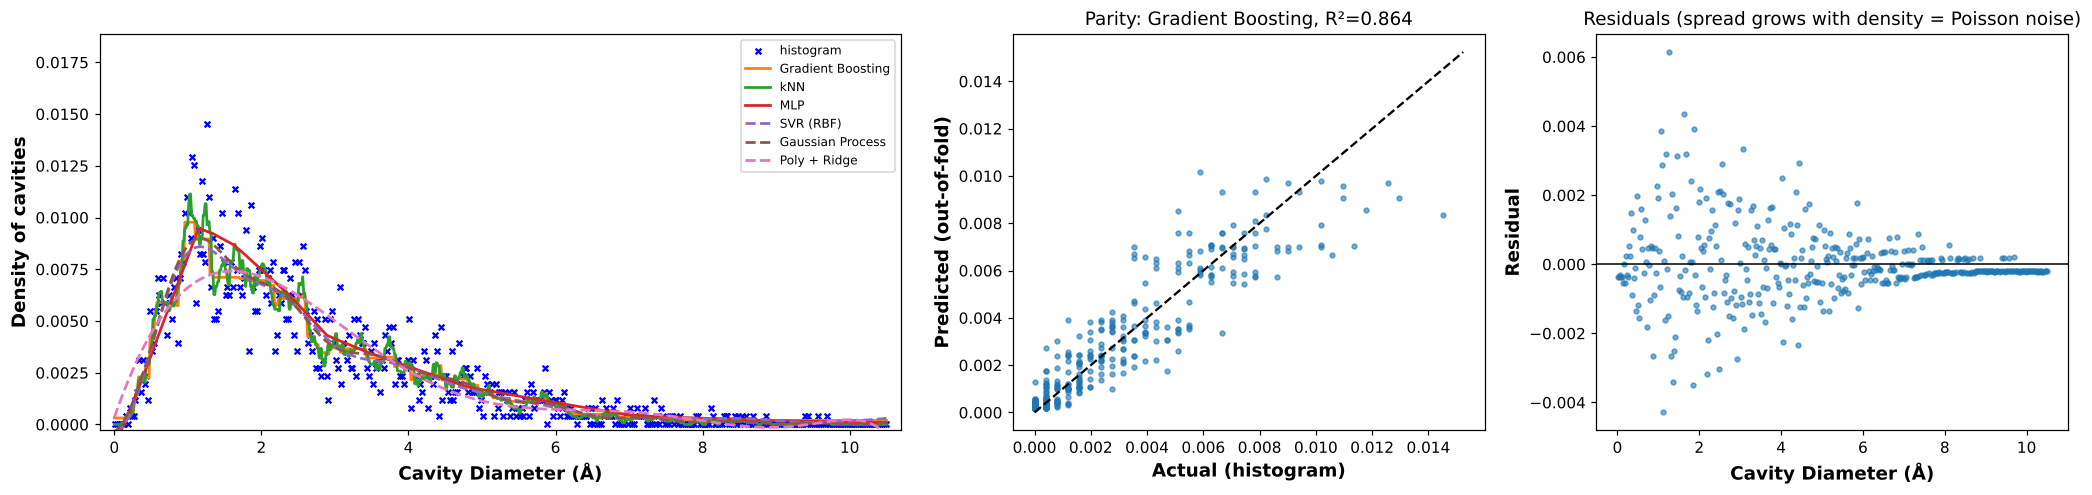

In [10]:
top3 = res.index[:3].tolist()                       # three lowest-MSE models
extra = ["SVR (RBF)", "Gaussian Process", "Poly + Ridge"]       # always shown on the first graph as well
to_plot = top3 + [m for m in extra if m not in top3]
cmap = plt.get_cmap("tab10")
xx = np.linspace(min_d, max_d, 800).reshape(-1, 1)

fig, ax = plt.subplots(1, 3, figsize=(19, 4.6), gridspec_kw={"width_ratios": [1.7, 1, 1]})
ax[0].scatter(bin_centers, hist_N, color="blue", marker="x", s=14, label="histogram")
for k, n in enumerate(to_plot):
    ls = "-" if n in top3 else "--"                    # solid = three lowest-MSE models, dashed = the others
    ax[0].plot(xx, clone(best_models[n]).fit(X, hist_N).predict(xx), color=cmap(k + 1), ls=ls, lw=1.8, label=n)
ax[0].set_xlabel("Cavity Diameter (Å)"); ax[0].set_ylabel("Density of cavities"); ax[0].legend(fontsize=8, loc="upper right")
ax[0].set_xlim(min_d - 0.2, max_d + 0.2); ax[0].set_ylim(-0.02 * hist_N.max(), 1.3 * hist_N.max())

best = top3[0]
oof = cross_val_predict(clone(best_models[best]), X, hist_N, cv=outer)
ax[1].scatter(hist_N, oof, s=10, alpha=0.6)
lim = [0, max(hist_N.max(), oof.max()) * 1.05]; ax[1].plot(lim, lim, "k--")
ax[1].set_xlabel("Actual (histogram)"); ax[1].set_ylabel("Predicted (out-of-fold)")
ax[1].set_title(f"Parity: {best}, R²={r2_score(hist_N, oof):.3f}")

ax[2].scatter(bin_centers, hist_N - oof, s=10, alpha=0.6); ax[2].axhline(0, color="k", lw=1)
ax[2].set_xlabel("Cavity Diameter (Å)"); ax[2].set_ylabel("Residual")
ax[2].set_title("Residuals (spread grows with density = Poisson noise)")
plt.tight_layout(); plt.show()

### Stress test — extrapolation (un-shuffled, contiguous folds)
Shuffled CV only tests *interpolation* between neighbouring bins. Here each fold is a contiguous diameter range (the first one contains the peak), so the model must predict a region it never saw. Hyperparameters are not re-tuned, and scores are pooled over all held-out blocks. This shows what the models can **not** do.

In [11]:
block = KFold(5, shuffle=False)
out = {}
for name in MODELS:
    pred = cross_val_predict(clone(best_models[name]), X, hist_N, cv=block)
    out[name] = {"MSE": mean_squared_error(hist_N, pred), "R²": r2_score(hist_N, pred)}
block_res = pd.DataFrame(out).T.sort_values("R²", ascending=False)
display(block_res.style.format({"MSE": "{:.3e}", "R²": "{:.3f}"}))

,MSE,R²
Gradient Boosting,3.380e-06,0.610
Random Forest,3.717e-06,0.572
kNN,3.813e-06,0.561
MLP,7.017e-06,0.191
Gaussian Process,7.024e-06,0.190
SVR (RBF),1.899e-05,-1.189
Poly + Ridge,1.047e-03,-119.645


### Q3 summary (recomputed for the current `bin_width`)

In [12]:
winners = res.index[res["Meets criterion"] == "yes"].tolist()
b = res.iloc[0]
print(f"bin_width = {bin_width} ({n_bins} bins, {hist.mean():.1f} cavities per bin on average)")
print(f"R² noise ceiling = {r2_ceiling:.3f}; noise-floor MSE = {noise_var:.3e}")
print(f"Lowest-MSE model: {res.index[0]}  (MSE = {b['MSE']:.3e}, R² = {b['R²']:.3f}, {b['MSE / noise floor']:.2f}x noise floor)")
print("Models meeting the success criterion:", ", ".join(winners) if winners else "none")
print(f"Best extrapolation (contiguous blocks): {block_res.index[0]} with pooled R² = {block_res['R²'].iloc[0]:.3f}")

bin_width = 0.025 (420 bins, 6.1 cavities per bin on average)
R² noise ceiling = 0.893; noise-floor MSE = 9.281e-07
Lowest-MSE model: Gradient Boosting  (MSE = 1.194e-06, R² = 0.861, 1.29x noise floor)
Models meeting the success criterion: Gradient Boosting, kNN, MLP, Gaussian Process, SVR (RBF)
Best extrapolation (contiguous blocks): Gradient Boosting with pooled R² = 0.610
